In [1]:
# load dataset

In [2]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from tensorflow.keras.applications import EfficientNetB1
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

DATASET_PATH = (
    "/kaggle/input/datasets/"
    "mnt0107/rice-pest-dataset-70-15-15-split"
)

TRAIN_DIR = os.path.join(DATASET_PATH, "train")
VAL_DIR = os.path.join(DATASET_PATH, "val")
TEST_DIR = os.path.join(DATASET_PATH, "test")

IMAGE_SIZE = (240, 240)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

val_ds = keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Found 2918 files belonging to 11 classes.


I0000 00:00:1791654115.880997      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791654115.884582      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 625 files belonging to 11 classes.
Found 631 files belonging to 11 classes.
Classes: ['brown plant hopper', 'paddy stem maggot', 'rice borer', 'rice gall midge', 'rice leaf caterpillar', 'rice leaf hopper', 'rice leaf roller', 'rice skipper', 'rice water weevil', 'rice whorl maggot', 'thrips']
Number of classes: 11


In [3]:
# EfficientNetB1 feature extractor

In [4]:
base_model = EfficientNetB1(
    weights="imagenet",
    include_top=False,
    input_shape=(240, 240, 3)
)

base_model.trainable = False

feature_extractor = keras.Sequential([
    keras.layers.Input(shape=(240, 240, 3)),
    base_model,
    keras.layers.GlobalAveragePooling2D()
])

feature_extractor.summary()

27018416/27018416 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb1 (Functional)     │ (None, 8, 8, 1280)     │     6,575,239 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,575,239 (25.08 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 6,575,239 (25.08 MB)

In [6]:
# Feature extraction

In [7]:
def extract_features(dataset, extractor):
    features = []
    labels = []

    for images, batch_labels in dataset:
        batch_features = extractor(
            images, training=False
        ).numpy()

        features.append(batch_features)
        labels.append(batch_labels.numpy())

    return (
        np.concatenate(features, axis=0),
        np.concatenate(labels, axis=0)
    )


# Extract features from all three splits
X_train, y_train = extract_features(
    train_ds, feature_extractor
)

X_val, y_val = extract_features(
    val_ds, feature_extractor
)

X_test, y_test = extract_features(
    test_ds, feature_extractor
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

print("\nTraining labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Test labels:", y_test.shape)

Training features: (2918, 1280)
Validation features: (625, 1280)
Test features: (631, 1280)

Training labels: (2918,)
Validation labels: (625,)
Test labels: (631,)


In [8]:
# scaling

In [9]:
scaler = StandardScaler()

# Scaler sirf training data par fit hoga
X_train_scaled = scaler.fit_transform(X_train)

# Validation aur test par sirf transform
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaled training features:", X_train_scaled.shape)
print("Scaled validation features:", X_val_scaled.shape)
print("Scaled test features:", X_test_scaled.shape)

Scaled training features: (2918, 1280)
Scaled validation features: (625, 1280)
Scaled test features: (631, 1280)


In [10]:
# training rbf-svm and tuning

In [11]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score

# Parameter combinations
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.001, 0.01, 0.1]
}

svm = SVC(kernel="rbf")

grid_search = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    scoring="accuracy",
    cv=3,
    n_jobs=-1,
    verbose=2
)

# Sirf training data par fit
grid_search.fit(X_train_scaled, y_train)

best_svm = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best CV accuracy:", grid_search.best_score_)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best parameters: {'C': 100, 'gamma': 'scale'}
Best CV accuracy: 0.9530481434957854


In [12]:
val_pred = best_svm.predict(X_val_scaled)

val_accuracy = accuracy_score(y_val, val_pred)
val_macro_f1 = f1_score(y_val, val_pred, average="macro")
val_weighted_f1 = f1_score(y_val, val_pred, average="weighted")

print(f"Validation Accuracy : {val_accuracy * 100:.2f}%")
print(f"Validation Macro F1  : {val_macro_f1:.4f}")
print(f"Validation Weighted F1: {val_weighted_f1:.4f}")

Validation Accuracy : 98.08%
Validation Macro F1  : 0.9740
Validation Weighted F1: 0.9807


In [13]:
import numpy as np
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    val_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    digits=4,
    zero_division=0
))

                       precision    recall  f1-score   support

   brown plant hopper     0.9787    0.9892    0.9840        93
    paddy stem maggot     0.9524    0.8696    0.9091        23
           rice borer     1.0000    0.9889    0.9944        90
      rice gall midge     0.9623    0.9808    0.9714        52
rice leaf caterpillar     0.9756    1.0000    0.9877        40
     rice leaf hopper     0.9688    0.9688    0.9688        64
     rice leaf roller     0.9773    0.9773    0.9773        44
         rice skipper     0.9756    0.9524    0.9639        42
    rice water weevil     0.9900    1.0000    0.9950        99
    rice whorl maggot     0.9630    0.9630    0.9630        27
               thrips     1.0000    1.0000    1.0000        51

             accuracy                         0.9808       625
            macro avg     0.9767    0.9718    0.9740       625
         weighted avg     0.9808    0.9808    0.9807       625



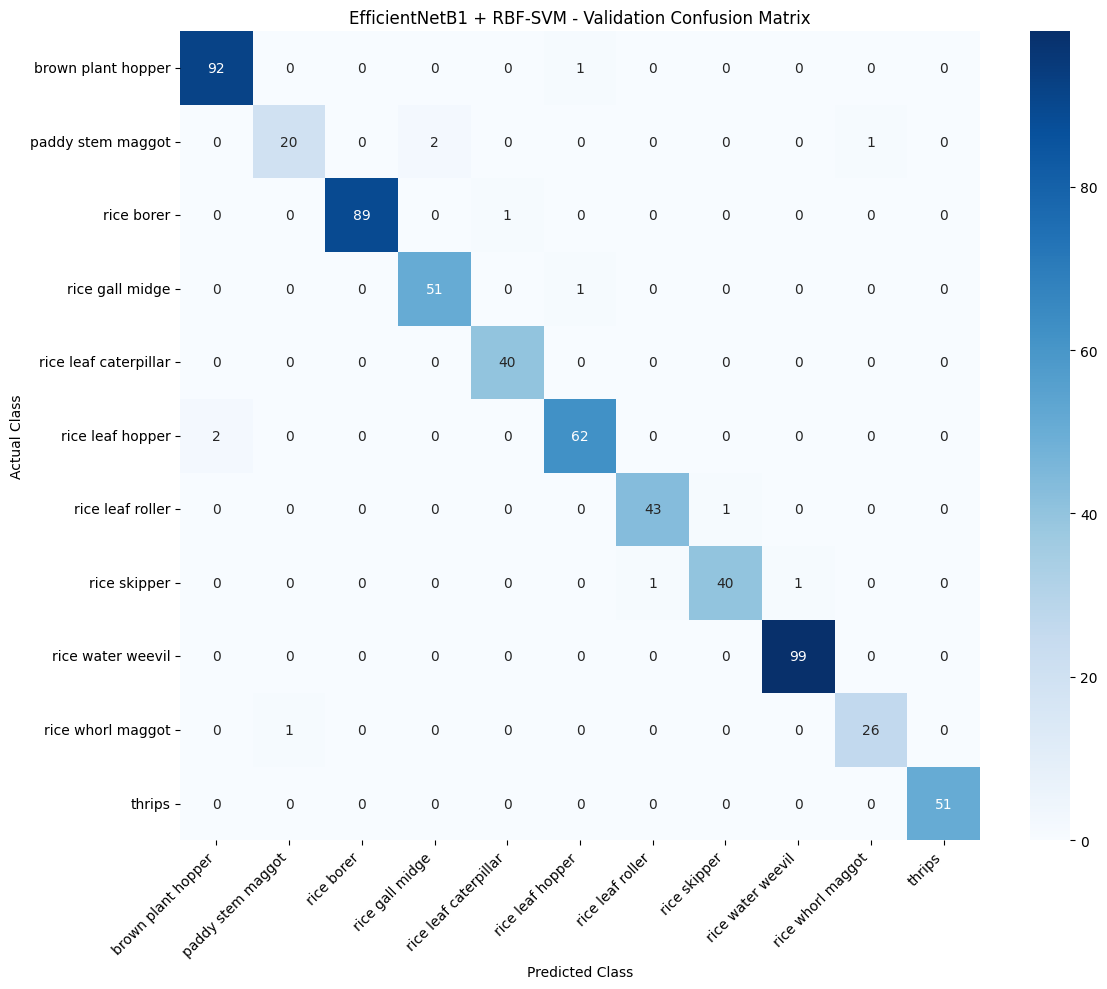

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_val = confusion_matrix(
    y_val,
    val_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_val,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("EfficientNetB1 + RBF-SVM - Validation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:
# save model

In [16]:
import os
import joblib

OUTPUT_DIR = "/kaggle/working"

# Feature extractor
feature_extractor.save(
    os.path.join(
        OUTPUT_DIR,
        "efficientnetb1_feature_extractor.keras"
    )
)

# Scaler
joblib.dump(
    scaler,
    os.path.join(
        OUTPUT_DIR,
        "efficientnetb1_svm_scaler.pkl"
    )
)

# Best SVM
joblib.dump(
    best_svm,
    os.path.join(
        OUTPUT_DIR,
        "efficientnetb1_rbf_svm.pkl"
    )
)

print("Feature extractor, scaler and SVM saved successfully.")

Feature extractor, scaler and SVM saved successfully.
[CV] END .................................C=0.1, gamma=0.001; total time=   9.6s
[CV] END ..................................C=0.1, gamma=0.01; total time=  12.3s
[CV] END ...................................C=0.1, gamma=0.1; total time=  11.1s
[CV] END ...................................C=1, gamma=0.001; total time=   7.0s
[CV] END ....................................C=1, gamma=0.01; total time=   9.6s
[CV] END .....................................C=1, gamma=0.1; total time=  11.6s
[CV] END ..................................C=10, gamma=0.001; total time=   7.6s
[CV] END ...................................C=10, gamma=0.01; total time=  10.4s
[CV] END ....................................C=10, gamma=0.1; total time=  11.8s
[CV] END .................................C=100, gamma=0.001; total time=   8.5s
[CV] END ..................................C=100, gamma=0.01; total time=  11.3s
[CV] END .................................C=0.1, gamma=

In [17]:
# test set evaluation

In [18]:
test_pred = best_svm.predict(X_test_scaled)

test_accuracy = accuracy_score(y_test, test_pred)
test_macro_f1 = f1_score(
    y_test, test_pred, average="macro"
)
test_weighted_f1 = f1_score(
    y_test, test_pred, average="weighted"
)

print(f"Test Accuracy : {test_accuracy * 100:.2f}%")
print(f"Macro F1      : {test_macro_f1:.4f}")
print(f"Weighted F1   : {test_weighted_f1:.4f}")

print("\nTest Classification Report:\n")

print(classification_report(
    y_test,
    test_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    digits=4,
    zero_division=0
))

Test Accuracy : 98.10%
Macro F1      : 0.9739
Weighted F1   : 0.9809

Test Classification Report:

                       precision    recall  f1-score   support

   brown plant hopper     0.9785    0.9785    0.9785        93
    paddy stem maggot     0.9130    0.9130    0.9130        23
           rice borer     1.0000    1.0000    1.0000        90
      rice gall midge     0.9815    1.0000    0.9907        53
rice leaf caterpillar     1.0000    1.0000    1.0000        40
     rice leaf hopper     0.9844    0.9692    0.9767        65
     rice leaf roller     0.9565    0.9778    0.9670        45
         rice skipper     0.9762    0.9535    0.9647        43
    rice water weevil     0.9804    1.0000    0.9901       100
    rice whorl maggot     1.0000    0.8889    0.9412        27
               thrips     0.9811    1.0000    0.9905        52

             accuracy                         0.9810       631
            macro avg     0.9774    0.9710    0.9739       631
         weighted